In [1]:
# Import de Bibliotecas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy.optimize import brentq

## Questão 1

### Letra C

Máximo de kro: 2.777778
Saturação de água nesse ponto: 0.444444


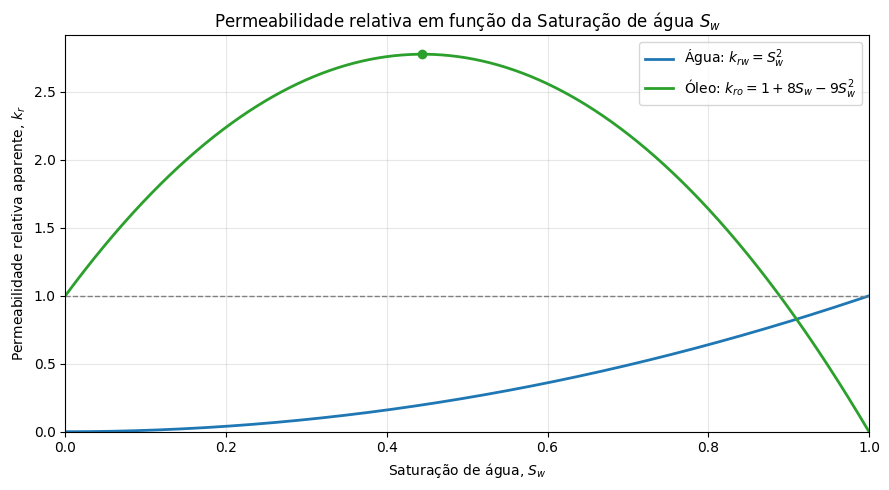

In [2]:
# Dados no SI
R = 100e-6       # m
L = 1e-2         # m
mu_w = 1e-3     # Pa.s
mu_o = 5e-3     # Pa.s

# Saturação de água
Sw = np.linspace(0, 1, 1001)
So = 1 - Sw

# Permeabilidades relativas
krw = Sw**2

kro = So**2 + 2 * (mu_o / mu_w) * Sw * So

# Máximo da curva do óleo
razao_mu = mu_o / mu_w

Sw_max = (razao_mu - 1) / (2 * razao_mu - 1)

kro_max = (
    (1 - Sw_max)**2
    + 2 * razao_mu * Sw_max * (1 - Sw_max)
)

print(f"Máximo de kro: {kro_max:.6f}")
print(f"Saturação de água nesse ponto: {Sw_max:.6f}")

# Gráfico
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    Sw, krw,
    color="tab:blue",
    linewidth=2,
    label=r"Água: $k_{rw}=S_w^2$"
)

ax.plot(
    Sw, kro,
    color="tab:green",
    linewidth=2,
    label=r"Óleo: $k_{ro}=1 + 8 S_w -9 S_w^2$"
)

ax.axhline(
    1,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.scatter(
    Sw_max, kro_max,
    color="tab:green",
    zorder=5
)

ax.set_xlabel(r"Saturação de água, $S_w$")
ax.set_ylabel(r"Permeabilidade relativa aparente, $k_r$")
ax.set_title("Permeabilidade relativa em função da Saturação de água $S_w$")

ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

# Salvar para inserir no LaTeX
fig.savefig("Q1fig1.png", dpi=300, bbox_inches="tight")

plt.show()

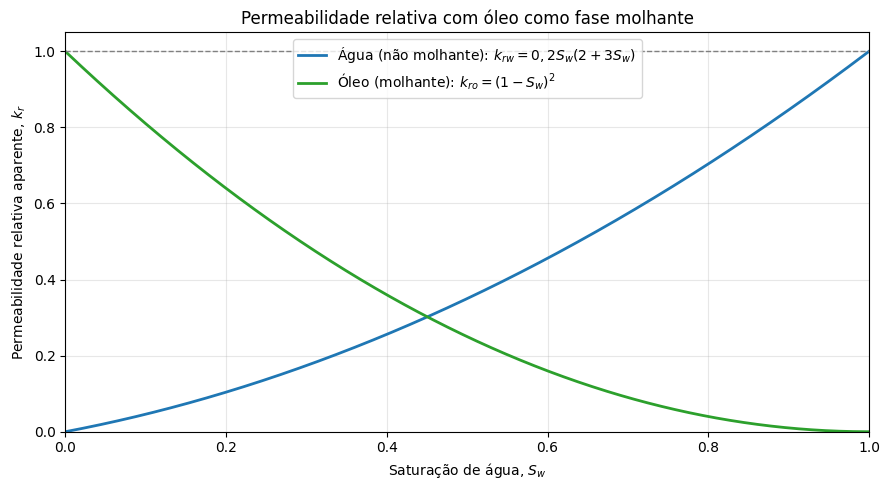

In [25]:
# Questão 1.d: óleo como fase molhante
# Mesmas viscosidades da letra C, em Pa.s
mu_w_d = 1e-3
mu_o_d = 5e-3

sw_d = np.linspace(0, 1, 1001)
so_d = 1 - sw_d

# Troca dos papéis das fases em relação à letra C
kro_d = so_d**2
krw_d = sw_d**2 + 2 * (mu_w_d / mu_o_d) * sw_d * so_d

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sw_d, krw_d, color="tab:blue", linewidth=2,
        label=r"Água (não molhante): $k_{rw}=0,2 S_w(2+3S_w)$")
ax.plot(sw_d, kro_d, color="tab:green", linewidth=2,
        label=r"Óleo (molhante): $k_{ro}=(1-S_w)^2$")
ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel(r"Saturação de água, $S_w$")
ax.set_ylabel(r"Permeabilidade relativa aparente, $k_r$")
ax.set_title("Permeabilidade relativa com óleo como fase molhante")
ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Questão 2

Os dados apresentados na tabela abaixo foram obtidos em condição de regime permanente com o objetivo de obter as curvas de permeabilidade relativa no escoamento bifásico de óleo e água.

*Dados adicionais obtidos nos experimentos:*  
Permeabilidade absoluta: K = 100 mD  
Diâmetro da amostra poroso: D = 3,2 cm  
Comprimento da amostra: L = 10 cm  
Porosidade da amostra: ∅ = 0.20  
Viscosidade da água: 𝜇𝑤 = 1.1 cP  
Viscosidade do óleo: 𝜇o = 5.0 cP  

In [4]:
df = pd.DataFrame({
    "Qo_cm3_h": [90, 75, 60, 45, 30, 15, 0],
    "Qa_cm3_h": [0, 5, 9, 20, 34, 85, 122],
    "dP_psi": [
        49.25, 91.29, 109.52, 123.30,
        137.05, 164.30, 147.00
    ],
    "Va_cm3": [2.17, 2.87, 3.63, 4.65, 5.93, 7.95, 9.86],
})

display(df)

,Qo_cm3_h,Qa_cm3_h,dP_psi,Va_cm3
0,90,0,49.25,2.17
1,75,5,91.29,2.87
2,60,9,109.52,3.63
3,45,20,123.30,4.65
4,30,34,137.05,5.93
5,15,85,164.30,7.95
6,0,122,147.00,9.86


In [5]:
## Utilitários de Unidades

# Conversões
MD_PARA_M2 = 9.869233e-16
PSI_PARA_PA = 6894.757293168
CM3H_PARA_M3S = 1e-6 / 3600

In [6]:
# Propriedades no SI
K = 100 * MD_PARA_M2   # m²
D = 3.2e-2            # m
L = 10e-2             # m
phi = 0.20

mu_a = 1.1e-3         # Pa.s
mu_o = 5.0e-3         # Pa.s

A = np.pi * D**2 / 4
V_poroso = phi * A * L

print(V_poroso)

print(f"Volume poroso: {V_poroso * 1e6:.6f} cm³")

1.608495438637974e-05
Volume poroso: 16.084954 cm³


In [7]:
# Converter os dados para o SI
df["Qo_m3_s"] = df["Qo_cm3_h"] * CM3H_PARA_M3S
df["Qa_m3_s"] = df["Qa_cm3_h"] * CM3H_PARA_M3S
df["dP_Pa"] = df["dP_psi"] * PSI_PARA_PA
df["Va_m3"] = df["Va_cm3"] * 1e-6

# Saturações
df["Sa"] = df["Va_m3"] / V_poroso
df["So"] = 1 - df["Sa"]

# Permeabilidades relativas
df["kra"] = (
    df["Qa_m3_s"] * mu_a * L
    / (K * A * df["dP_Pa"])
)

df["kro"] = (
    df["Qo_m3_s"] * mu_o * L
    / (K * A * df["dP_Pa"])
)

display(df.round(6))

,Qo_cm3_h,Qa_cm3_h,dP_psi,Va_cm3,Qo_m3_s,Qa_m3_s,dP_Pa,Va_m3,Sa,So,kra,kro
0,90,0,49.25,2.17,0.0,0.0,3.395668e+05,0.000002,0.134909,0.865091,0.000000,0.463780
1,75,5,91.29,2.87,0.0,0.0,6.294224e+05,0.000003,0.178428,0.821572,0.003058,0.208503
2,60,9,109.52,3.63,0.0,0.0,7.551138e+05,0.000004,0.225677,0.774323,0.004588,0.139038
3,45,20,123.30,4.65,0.0,0.0,8.501236e+05,0.000005,0.289090,0.710910,0.009057,0.092624
4,30,34,137.05,5.93,0.0,0.0,9.449265e+05,0.000006,0.368668,0.631332,0.013852,0.055554
5,15,85,164.30,7.95,0.0,0.0,1.132809e+06,0.000008,0.494251,0.505749,0.028885,0.023170
6,0,122,147.00,9.86,0.0,0.0,1.013529e+06,0.000010,0.612995,0.387005,0.046338,0.000000


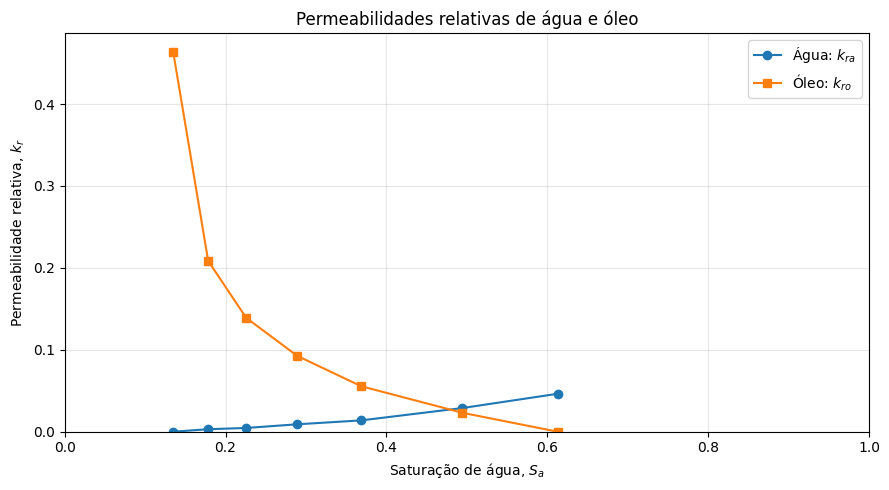

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    df["Sa"], df["kra"], "o-",
    label=r"Água: $k_{ra}$"
)

ax.plot(
    df["Sa"], df["kro"], "s-",
    label=r"Óleo: $k_{ro}$"
)

ax.set_xlabel(r"Saturação de água, $S_a$")
ax.set_ylabel(r"Permeabilidade relativa, $k_r$")
ax.set_title("Permeabilidades relativas de água e óleo")

ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Questão 3

Considere um meio poroso cilíndrico com raio 𝑟 = 5𝑐𝑚, comprimento 𝐿 = 40𝑐𝑚, permeabilidade de 𝐾 = 500 𝑚𝐷 e porosidade de ∅ = 20%. A saturação inicial de óleo é uniforme e igual a 𝑆𝑜 = 0.85; observe que a saturação de água é baixa o suficiente que a água residual existente no meio poroso não escoa.  
Água é injetada a uma vazão de 𝑄 = 1 𝑚𝑙/𝑠. A viscosidade do óleo é igual a 𝜇0 = 10𝑐𝑃 e a viscosidade da água é igual a 𝜇𝑤 = 1𝑐𝑃.    

Os dados de permeabilidade relativa em função da saturação de água do meio são apresentados na tabela
abaixo.  

Pede-se:
1. Construa um gráfico com as permeabilidades relativas dadas na tabela acima;
2. Desprezando o efeito de pressão capilar, determine a vazão fracional de água em função da saturação de água. Apresente o resultado em forma de uma tabela e um gráfico.
3. Determine a saturação de água na frente de propagação 𝑆𝑎.
4. Determine a velocidade de propagação da frente e o tempo de “breaktrough” da água.


In [9]:
df = pd.DataFrame({
    "Sw":  [0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80],
    "kro": [0.96, 0.69, 0.49, 0.33, 0.20, 0.11, 0.05, 0.00],
    "krw": [0.00, 0.005, 0.030, 0.070, 0.130, 0.190, 0.260, 0.350],
})

display(df)

,Sw,kro,krw
0,0.15,0.96,0.000
1,0.20,0.69,0.005
2,0.30,0.49,0.030
3,0.40,0.33,0.070
4,0.50,0.20,0.130
5,0.60,0.11,0.190
6,0.70,0.05,0.260
7,0.80,0.00,0.350


### Letra A

1. Construa um gráfico com as permeabilidades relativas dadas na tabela acima;

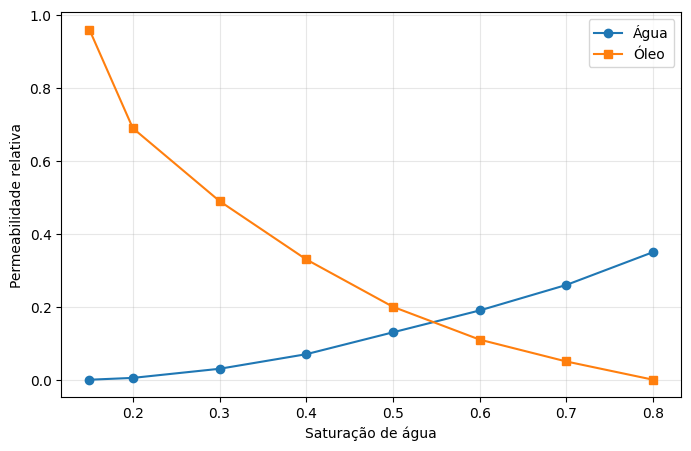

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(df["Sw"], df["krw"], "o-", label="Água")
plt.plot(df["Sw"], df["kro"], "s-", label="Óleo")

plt.xlabel("Saturação de água")
plt.ylabel("Permeabilidade relativa")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Letra B

2. Desprezando o efeito de pressão capilar, determine a vazão fracional de água em função da saturação de água. Apresente o resultado em forma de uma tabela e um gráfico.

In [11]:
# Geometria e vazão no SI
r = 0.05       # m
L = 0.40       # m
phi = 0.20
Q = 1e-6       # m³/s

# Viscosidades na mesma unidade
mu_w = 1e-3    # Pa.s
mu_o = 10e-3   # Pa.s

Swi = 0.15
A = np.pi * r**2

,Sw,kro,krw,fw
0,0.15,0.96,0.000,0.000000
1,0.20,0.69,0.005,0.067568
2,0.30,0.49,0.030,0.379747
3,0.40,0.33,0.070,0.679612
4,0.50,0.20,0.130,0.866667
5,0.60,0.11,0.190,0.945274
6,0.70,0.05,0.260,0.981132
7,0.80,0.00,0.350,1.000000


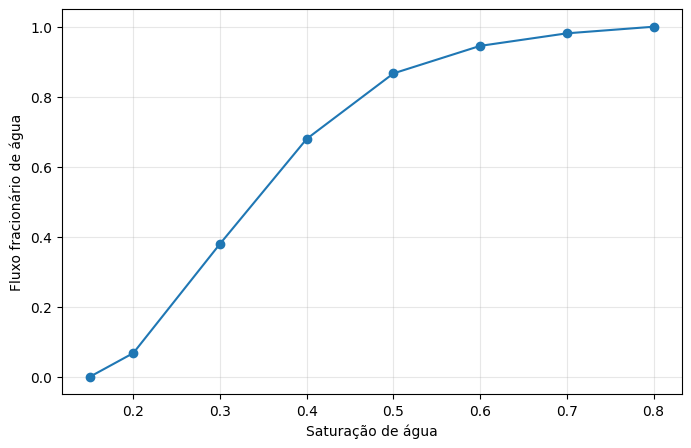

In [12]:
df["fw"] = (
    (df["krw"] / mu_w)
    / (df["krw"] / mu_w + df["kro"] / mu_o)
)

display(df.round(6))

plt.figure(figsize=(8, 5))
plt.plot(df["Sw"], df["fw"], "o-")

plt.xlabel("Saturação de água")
plt.ylabel("Fluxo fracionário de água")
plt.grid(alpha=0.3)
plt.show()

### Letra C

In [13]:
krw = PchipInterpolator(df["Sw"], df["krw"], extrapolate=False)
kro = PchipInterpolator(df["Sw"], df["kro"], extrapolate=False)

dkrw = krw.derivative()
dkro = kro.derivative()

def fw(Sw):
    lw = krw(Sw) / mu_w
    lo = kro(Sw) / mu_o
    return lw / (lw + lo)

def dfw(Sw):
    lw = krw(Sw) / mu_w
    lo = kro(Sw) / mu_o

    dlw = dkrw(Sw) / mu_w
    dlo = dkro(Sw) / mu_o

    return (dlw * lo - lw * dlo) / (lw + lo)**2

fw_i = float(fw(Swi))

def condicao_frente(Sw):
    return dfw(Sw) - (fw(Sw) - fw_i) / (Sw - Swi)

Swf = brentq(condicao_frente, 0.30, 0.50)

fw_f = float(fw(Swf))
m = (fw_f - fw_i) / (Swf - Swi)

print(f"Sw da frente = {Swf:.6f}")
print(f"fw na frente = {fw_f:.6f}")
print(f"Inclinação da tangente = {m:.6f}")

Sw da frente = 0.378514
fw na frente = 0.624043
Inclinação da tangente = 2.730875


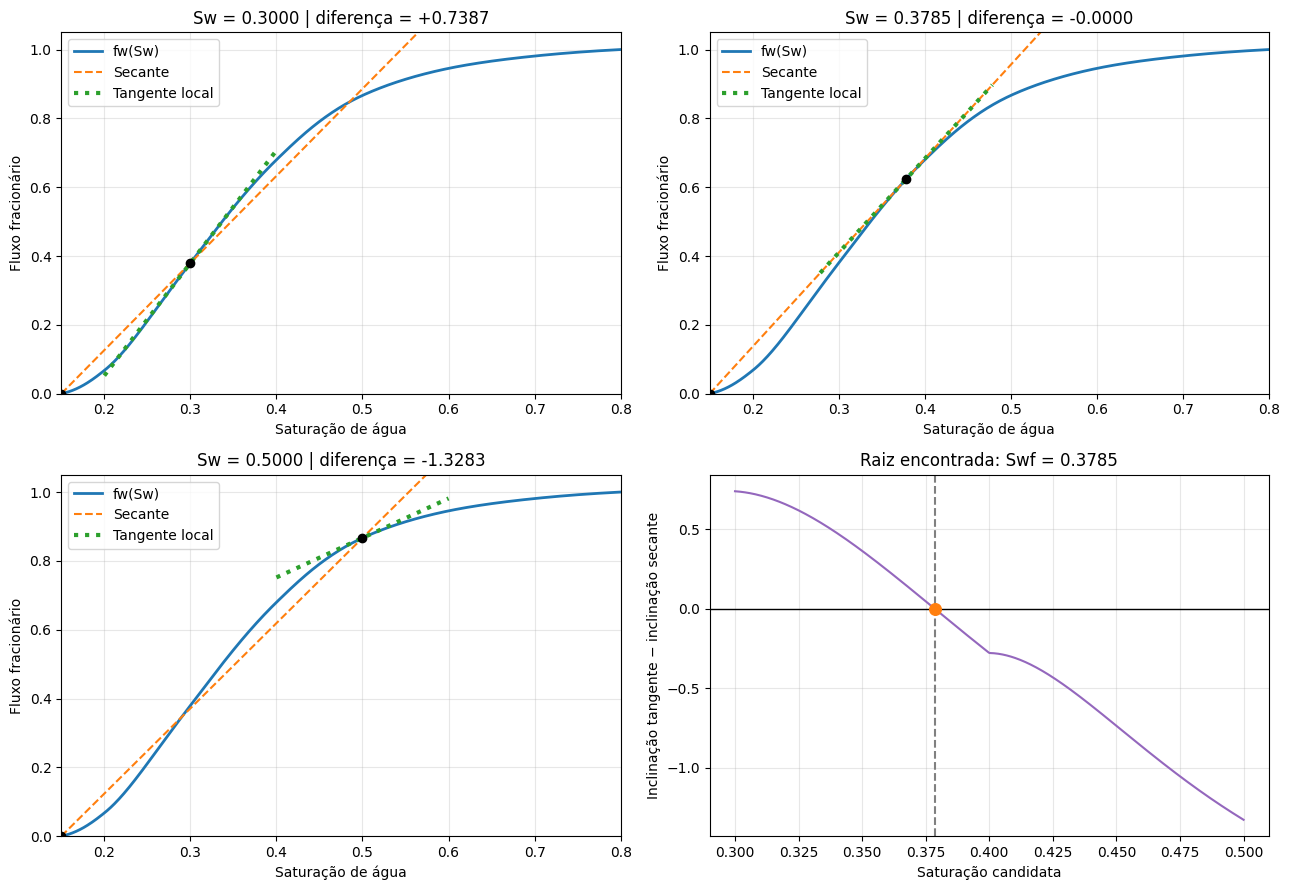

In [14]:
S = np.linspace(Swi, 0.8, 600)

fig, axs = plt.subplots(2, 2, figsize=(13, 9))

# Três candidatos: antes, na solução e depois
for ax, s in zip(axs.flat[:3], [0.30, Swf, 0.50]):

    f = float(fw(s))

    # Inclinação da reta que parte do estado inicial
    m_sec = (f - fw_i) / (s - Swi)

    # Inclinação da curva no ponto candidato
    m_tan = float(dfw(s))

    # Curva de fluxo fracionário
    ax.plot(S, fw(S), color="tab:blue", lw=2, label="fw(Sw)")

    # Secante: y = y_inicial + m_sec * (x - x_inicial)
    ax.plot(
        S, fw_i + m_sec * (S - Swi),
        "--", color="tab:orange", label="Secante"
    )

    # Tangente local: y = f(s) + f'(s) * (x - s)
    local = np.linspace(
        max(Swi, s - 0.10),
        min(0.8, s + 0.10),
        100
    )

    ax.plot(
        local, f + m_tan * (local - s),
        ":", color="tab:green", lw=3, label="Tangente local"
    )

    ax.scatter([Swi, s], [fw_i, f], color="black", zorder=5)

    ax.set(
        title=f"Sw = {s:.4f} | diferença = {m_tan - m_sec:+.4f}",
        xlabel="Saturação de água",
        ylabel="Fluxo fracionário",
        xlim=(Swi, 0.8),
        ylim=(0, 1.05)
    )

    ax.grid(alpha=0.3)
    ax.legend()

# Função que o brentq zera
ax = axs[1, 1]

S_busca = np.linspace(0.30, 0.50, 600)

ax.plot(S_busca, condicao_frente(S_busca), color="tab:purple")
ax.axhline(0, color="black", lw=1)
ax.axvline(Swf, color="gray", linestyle="--")
ax.scatter([Swf], [0], color="tab:orange", s=70, zorder=5)

ax.set(
    title=f"Raiz encontrada: Swf = {Swf:.4f}",
    xlabel="Saturação candidata",
    ylabel="Inclinação tangente − inclinação secante"
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Letra D

In [15]:
v_frente = Q / (phi * A) * m
t_bt = L / v_frente

print(f"Velocidade da frente: {v_frente * 100:.6f} cm/s")
print(f"Breakthrough: {t_bt:.2f} s")
print(f"Breakthrough: {t_bt / 60:.2f} min")

Velocidade da frente: 0.173853 cm/s
Breakthrough: 230.08 s
Breakthrough: 3.83 min


## Questão 4

In [16]:
# Geometria
L = 200.0      # m
W = 50.0       # m
H = 10.0       # m

# Propriedades e vazão
phi = 0.20
K_mD = 500.0   # mD
Qt = 100.0     # m³/dia

# Viscosidades na mesma unidade
mu_w = 1.0     # cP
mu_o = 10.0    # cP

# Saturações
Swi = 0.20
Sor = 0.25

# Grandezas derivadas
A = W * H
Vp = phi * A * L
OOIP = Vp * (1 - Swi)

DeltaS = 1 - Swi - Sor
Sw_max = 1 - Sor

print(f"Área transversal: {A:.2f} m²")
print(f"Volume poroso: {Vp:.2f} m³")
print(f"Volume inicial de óleo: {OOIP:.2f} m³")

Área transversal: 500.00 m²
Volume poroso: 20000.00 m³
Volume inicial de óleo: 16000.00 m³


In [17]:
def Se(Sw):
    """Saturação efetiva."""
    return (np.asarray(Sw) - Swi) / DeltaS


def krw(Sw):
    return 0.40 * Se(Sw)**3


def kro(Sw):
    return 0.90 * (1 - Se(Sw))**2


def dkrw(Sw):
    """Derivada de krw em relação a Sw."""
    return 1.20 * Se(Sw)**2 / DeltaS


def dkro(Sw):
    """Derivada de kro em relação a Sw."""
    return -1.80 * (1 - Se(Sw)) / DeltaS


def fw(Sw, mu_oleo=10.0):
    lw = krw(Sw) / mu_w
    lo = kro(Sw) / mu_oleo

    return lw / (lw + lo)


def dfw(Sw, mu_oleo=10.0):
    lw = krw(Sw) / mu_w
    lo = kro(Sw) / mu_oleo

    dlw = dkrw(Sw) / mu_w
    dlo = dkro(Sw) / mu_oleo

    return (dlw * lo - lw * dlo) / (lw + lo)**2

### Letra A

In [18]:
u_t = Qt / A

print(f"Velocidade de Darcy: {u_t:.6f} m/dia")
print(f"Velocidade de Darcy: {u_t / 86400:.6e} m/s")

Velocidade de Darcy: 0.200000 m/dia
Velocidade de Darcy: 2.314815e-06 m/s


### Letra B

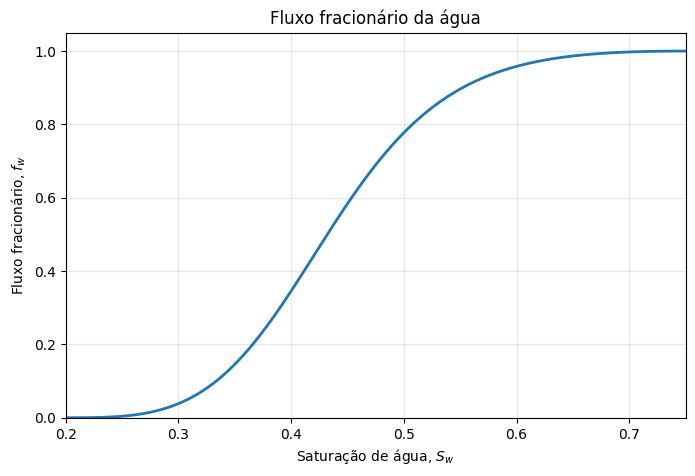

In [19]:
Sw_grid = np.linspace(Swi, Sw_max, 1000)

plt.figure(figsize=(8, 5))

plt.plot(
    Sw_grid,
    fw(Sw_grid, mu_o),
    linewidth=2
)

plt.xlabel(r"Saturação de água, $S_w$")
plt.ylabel(r"Fluxo fracionário, $f_w$")
plt.title("Fluxo fracionário da água")

plt.xlim(Swi, Sw_max)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)

plt.show()

### Letra C

Saturação efetiva da frente: 0.575790
Saturação de água da frente: 0.516685
Fluxo fracionário na frente: 0.825011
Inclinação da tangente: 2.605150


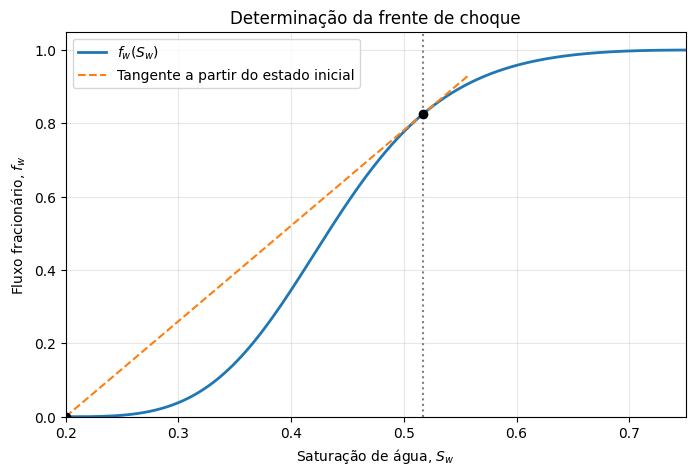

In [20]:
def condicao_frente(Sw, mu_oleo=10.0):
    fw_inicial = fw(Swi, mu_oleo)

    inclinacao_secante = (
        (fw(Sw, mu_oleo) - fw_inicial)
        / (Sw - Swi)
    )

    return dfw(Sw, mu_oleo) - inclinacao_secante


# Afastamento dos extremos para evitar a divisão por zero em Swi
eps = 1e-6 * DeltaS

Swf = brentq(
    condicao_frente,
    Swi + eps,
    Sw_max - eps,
    args=(mu_o,)
)

fw_i = float(fw(Swi, mu_o))
fw_f = float(fw(Swf, mu_o))

m = (fw_f - fw_i) / (Swf - Swi)

print(f"Saturação efetiva da frente: {float(Se(Swf)):.6f}")
print(f"Saturação de água da frente: {Swf:.6f}")
print(f"Fluxo fracionário na frente: {fw_f:.6f}")
print(f"Inclinação da tangente: {m:.6f}")

# Gráfico
Sw_reta = np.linspace(Swi, Swf + 0.04, 200)

plt.figure(figsize=(8, 5))

plt.plot(
    Sw_grid, fw(Sw_grid, mu_o),
    label=r"$f_w(S_w)$",
    linewidth=2
)

plt.plot(
    Sw_reta,
    fw_i + m * (Sw_reta - Swi),
    "--",
    label="Tangente a partir do estado inicial"
)

plt.scatter(
    [Swi, Swf],
    [fw_i, fw_f],
    color="black",
    zorder=5
)

plt.axvline(Swf, color="gray", linestyle=":")

plt.xlabel(r"Saturação de água, $S_w$")
plt.ylabel(r"Fluxo fracionário, $f_w$")
plt.title("Determinação da frente de choque")

plt.xlim(Swi, Sw_max)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

### Letra D

In [21]:
v_frente = Qt / (phi * A) * m

t_bt = L / v_frente

PVI_bt = Qt * t_bt / Vp

print(f"Velocidade da frente: {v_frente:.6f} m/dia")
print(f"Breakthrough: {t_bt:.6f} dias")
print(f"Breakthrough: {PVI_bt:.6f} PVI")

Velocidade da frente: 2.605150 m/dia
Breakthrough: 76.771006 dias
Breakthrough: 0.383855 PVI


### Letra E

In [22]:
# Antes do breakthrough, toda a vazão produzida é óleo
Np_bt = Qt * t_bt

# Recuperação em relação ao óleo inicialmente presente
FR_bt = Np_bt / OOIP

print(f"Óleo produzido até o breakthrough: {Np_bt:.2f} m³")
print(f"Volume inicial de óleo: {OOIP:.2f} m³")
print(f"Fator de recuperação: {100 * FR_bt:.2f}%")

Óleo produzido até o breakthrough: 7677.10 m³
Volume inicial de óleo: 16000.00 m³
Fator de recuperação: 47.98%


### Letra F

mu_o_cP,10.0,2.0
Swf,0.516685,0.631752
fw_frente,0.825011,0.902936
m,2.605150,2.091331
v_frente_m_dia,2.605150,2.091331
t_bt_dias,76.771006,95.632882
PVI_bt,0.383855,0.478164
Np_bt_m3,7677.100602,9563.288165
FR_bt_pct,47.981879,59.770551


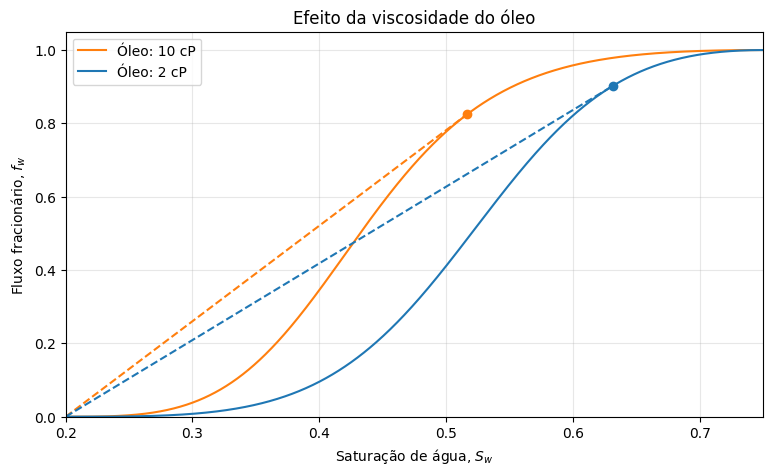

In [23]:
def resolver_caso(mu_oleo):

    swf = brentq(
        condicao_frente,
        Swi + eps,
        Sw_max - eps,
        args=(mu_oleo,)
    )

    fwf = float(fw(swf, mu_oleo))
    fwi = float(fw(Swi, mu_oleo))

    inclinacao = (fwf - fwi) / (swf - Swi)

    velocidade = Qt / (phi * A) * inclinacao
    tempo = L / velocidade

    volume_oleo = Qt * tempo
    recuperacao = volume_oleo / OOIP

    return {
        "mu_o_cP": mu_oleo,
        "Swf": swf,
        "fw_frente": fwf,
        "m": inclinacao,
        "v_frente_m_dia": velocidade,
        "t_bt_dias": tempo,
        "PVI_bt": Qt * tempo / Vp,
        "Np_bt_m3": volume_oleo,
        "FR_bt_pct": 100 * recuperacao,
    }


comparacao = pd.DataFrame([
    resolver_caso(10.0),
    resolver_caso(2.0)
])

display(comparacao.set_index("mu_o_cP").T.round(6))

# Comparação gráfica
plt.figure(figsize=(9, 5))

for viscosidade, cor in [(10.0, "tab:orange"), (2.0, "tab:blue")]:

    caso = resolver_caso(viscosidade)

    plt.plot(
        Sw_grid,
        fw(Sw_grid, viscosidade),
        color=cor,
        label=f"Óleo: {viscosidade:g} cP"
    )

    s_reta = np.linspace(Swi, caso["Swf"], 200)

    plt.plot(
        s_reta,
        caso["m"] * (s_reta - Swi),
        "--",
        color=cor
    )

    plt.scatter(
        caso["Swf"],
        caso["fw_frente"],
        color=cor,
        zorder=5
    )

plt.xlabel(r"Saturação de água, $S_w$")
plt.ylabel(r"Fluxo fracionário, $f_w$")
plt.title("Efeito da viscosidade do óleo")

plt.xlim(Swi, Sw_max)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()

plt.show()
